# Scenario 1: Retail Inventory Analysis

**Goal:** help a store manager understand stock movement: inventory turnover, slow-moving items, stockout risk, and visualizations.

**Approach:** I tried two prompting strategies, a short *vague* prompt and a *detailed, context-rich* prompt, then ran both outputs on the same test data to compare them.

## Test data
The real store data isn't available, so I generated 200 products that match the given structure. I also deliberately added the kinds of problems real data has: a missing restock date, a date stored in a different format, products with **zero sales**, and a negative stock level from a data-entry error. That way the error handling actually gets tested.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 200
categories = ['Electronics', 'Grocery', 'Apparel', 'Home', 'Toys']

inventory_df = pd.DataFrame({
    'product_id': [f'P{i:04d}' for i in range(n)],
    'category': rng.choice(categories, n),
    'stock_level': rng.integers(0, 500, n),
    'last_restock_date': pd.to_datetime('2026-11-20') - pd.to_timedelta(rng.integers(1, 180, n), unit='D'),
    'sales_last_30_days': rng.poisson(rng.choice([2, 15, 60, 150], n)),
    'supplier_lead_time': rng.integers(3, 30, n),
    'unit_cost': rng.uniform(2, 300, n).round(2),
})
inventory_df['last_restock_date'] = inventory_df['last_restock_date'].dt.strftime('%Y-%m-%d')

# Messy real-world rows
inventory_df.loc[5, 'last_restock_date'] = None            # missing date
inventory_df.loc[6, 'last_restock_date'] = '11/02/2026'    # different date format
inventory_df.loc[7:12, 'sales_last_30_days'] = 0           # items that didn't sell
inventory_df.loc[13, 'stock_level'] = -4                   # data-entry error

inventory_df.head()

,product_id,category,stock_level,last_restock_date,sales_last_30_days,supplier_lead_time,unit_cost
0,P0000,Electronics,183,2026-05-25,55,28,14.00
1,P0001,Home,454,2026-07-03,161,11,135.99
2,P0002,Home,247,2026-09-23,55,9,267.96
3,P0003,Apparel,349,2026-05-30,0,17,225.39
4,P0004,Apparel,228,2026-08-22,155,14,297.56


---
## Attempt 1: Vague prompt

### Your Prompt:
> *Write Python code to analyze inventory turnover, find slow-moving items, predict stockouts, and make charts. The dataframe has product_id, category, stock_level, last_restock_date, sales_last_30_days, supplier_lead_time, unit_cost.*

**Why I wrote it this way:** this is how most people first ask an AI: just the task and the column names. I wanted a baseline to see what the AI assumes when I don't give it business rules.

### Generated Code:

In [2]:
# ---- AI-generated code (vague prompt) ----
from datetime import datetime

def analyze_inventory(df):
    df['last_restock_date'] = pd.to_datetime(df['last_restock_date'])
    df['days_since_restock'] = (datetime.now() - df['last_restock_date']).dt.days

    # Turnover = sales / stock
    df['turnover_rate'] = df['sales_last_30_days'] / df['stock_level']

    # Slow movers: turnover below 0.5
    slow_moving = df[df['turnover_rate'] < 0.5]

    # Stockout prediction
    df['daily_sales'] = df['sales_last_30_days'] / 30
    df['days_until_stockout'] = df['stock_level'] / df['daily_sales']
    stockout_risk = df[df['days_until_stockout'] < df['supplier_lead_time']]

    df['turnover_rate'].hist()
    plt.title('Inventory Turnover')
    plt.show()

    return df, slow_moving, stockout_risk

### Testing the vague-prompt code

In [3]:
try:
    result_a, slow_a, risk_a = analyze_inventory(inventory_df.copy())
    print("Ran without crashing.")
except Exception as e:
    print("FAILED:", type(e).__name__, "-", e)

FAILED: ValueError - time data "11/02/2026" doesn't match format "%Y-%m-%d", at position 6. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.


**Problems I found:**
- **Date parsing crashed.** `pd.to_datetime()` couldn't handle the mixed date formats (`'2026-11-02'` vs. `'11/02/2026'`), so the whole function failed on real-looking data.
- **`datetime.now()`** makes results change every day the notebook runs. Reports aren't reproducible, and the result depends on the computer's clock and timezone.
- No checks for division by zero (zero sales or zero stock gives `inf`), negative stock, or missing columns.
- One basic histogram, and "turnover" isn't defined in a standard way (no time period, no annualizing).

---
## Attempt 2: Detailed, context-rich prompt

### Your Prompt:
> *You are a senior retail data analyst. Write a well-documented pandas function for a store manager.*
>
> *Data: one row per product with `product_id`, `category`, `stock_level` (units on hand), `last_restock_date` (string, formats may vary, may be missing), `sales_last_30_days` (units), `supplier_lead_time` (days), `unit_cost` ($).*
>
> *Requirements:*
> *1. Take an `as_of_date` parameter instead of using today's date, so results are reproducible.*
> *2. Turnover: 30-day turnover = units sold ÷ units on hand, plus an annualized version (×365/30). Also compute days of supply.*
> *3. Slow-moving: days of supply > 90 OR in the bottom 20% of turnover within its category.*
> *4. Stockout risk: days of supply < lead time + a 7-day safety buffer. Return a risk level (High/Medium/Low).*
> *5. Error handling: validate required columns, coerce bad dates to NaT and report them, handle division by zero (zero sales → infinite supply, zero stock → already out), and flag negative stock as a data error instead of using it.*
> *6. Visualizations: turnover by category, days of supply vs. lead time (scatter, colored by risk), and the top 10 products at risk by value.*
> *Return a results DataFrame and a dict of data-quality issues.*

**Why I wrote it this way:** I gave the AI a **role**, explained the **data quirks** I already knew about, and turned vague words like "slow-moving" and "stockout" into **specific business rules**. I also asked for error handling and specific charts up front, instead of hoping the AI would think of them.

### Generated Code:

In [4]:
# ---- AI-generated code (detailed prompt) ----
REQUIRED_COLS = ['product_id', 'category', 'stock_level', 'last_restock_date',
                 'sales_last_30_days', 'supplier_lead_time', 'unit_cost']

def analyze_inventory_v2(df, as_of_date, safety_buffer_days=7, slow_supply_days=90):
    """Inventory turnover, slow movers and stockout risk.

    Returns (results_df, issues_dict).
    """
    missing = [c for c in REQUIRED_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    df = df.copy()
    issues = {}
    as_of = pd.Timestamp(as_of_date)

    # --- Dates: parse each value flexibly, bad/missing -> NaT
    df['last_restock_date'] = pd.to_datetime(df['last_restock_date'], format='mixed', errors='coerce')
    issues['unparseable_or_missing_dates'] = df.loc[df['last_restock_date'].isna(), 'product_id'].tolist()
    df['days_since_restock'] = (as_of - df['last_restock_date']).dt.days

    # --- Numeric sanity checks
    for col in ['stock_level', 'sales_last_30_days', 'supplier_lead_time', 'unit_cost']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    negative = df['stock_level'] < 0
    issues['negative_stock'] = df.loc[negative, 'product_id'].tolist()
    df.loc[negative, 'stock_level'] = np.nan          # don't trust bad values

    # --- Turnover and days of supply (safe division)
    daily_sales = df['sales_last_30_days'] / 30
    df['turnover_30d'] = np.where(df['stock_level'] > 0,
                                  df['sales_last_30_days'] / df['stock_level'], np.nan)
    df['turnover_annualized'] = df['turnover_30d'] * 365 / 30
    df['days_of_supply'] = np.where(daily_sales > 0, df['stock_level'] / daily_sales, np.inf)
    df.loc[df['stock_level'] == 0, 'days_of_supply'] = 0      # already out of stock
    df['inventory_value'] = df['stock_level'] * df['unit_cost']

    # --- Slow movers: >90 days supply OR bottom 20% turnover in category
    cat_p20 = df.groupby('category')['turnover_30d'].transform(lambda s: s.quantile(0.20))
    df['slow_moving'] = (df['days_of_supply'] > slow_supply_days) | (df['turnover_30d'] <= cat_p20)

    # --- Stockout risk vs. lead time + buffer
    threshold = df['supplier_lead_time'] + safety_buffer_days
    df['stockout_risk'] = np.select(
        [df['days_of_supply'] <= df['supplier_lead_time'],
         df['days_of_supply'] <= threshold],
        ['High', 'Medium'], default='Low')
    df.loc[df['stock_level'].isna(), 'stockout_risk'] = 'Unknown (bad data)'

    return df, issues


def plot_inventory(results):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    results.groupby('category')['turnover_annualized'].median().sort_values().plot(
        kind='barh', ax=axes[0], color='steelblue')
    axes[0].set_title('Median Annualized Turnover by Category')
    axes[0].set_xlabel('Turns per year')

    colors = {'High': 'red', 'Medium': 'orange', 'Low': 'green'}
    plot_df = results[np.isfinite(results['days_of_supply'])]
    for risk, color in colors.items():
        sub = plot_df[plot_df['stockout_risk'] == risk]
        axes[1].scatter(sub['supplier_lead_time'], sub['days_of_supply'], c=color, label=risk, alpha=0.6)
    axes[1].plot([0, 30], [0, 30], 'k--', label='Supply = lead time')
    axes[1].set_ylim(0, 120)
    axes[1].set_title('Days of Supply vs. Supplier Lead Time')
    axes[1].set_xlabel('Lead time (days)'); axes[1].set_ylabel('Days of supply'); axes[1].legend()

    top = results[results['stockout_risk'] == 'High'].nlargest(10, 'inventory_value')
    axes[2].barh(top['product_id'], top['inventory_value'], color='red')
    axes[2].set_title('Top 10 High-Risk Products by Inventory Value')
    axes[2].set_xlabel('Inventory value ($)')

    plt.tight_layout()
    plt.show()

### Testing the detailed-prompt code

In [5]:
results, issues = analyze_inventory_v2(inventory_df, as_of_date='2026-11-20')
print("Data-quality issues found:", issues)
print()
print(results['stockout_risk'].value_counts())
print("Slow-moving items:", results['slow_moving'].sum())

Data-quality issues found: {'unparseable_or_missing_dates': ['P0005'], 'negative_stock': ['P0013']}

stockout_risk
Low                   188
High                    8
Medium                  3
Unknown (bad data)      1
Name: count, dtype: int64
Slow-moving items: 131


---
## Follow-up Prompts:
1. *"The vague version crashed on `'11/02/2026'`. Make date parsing handle mixed formats without failing the whole run."* → led to `format='mixed', errors='coerce'` plus reporting the bad rows.
2. *"What happens when sales are 0 or stock is 0?"* → the AI added `np.where` safe division: zero sales means infinite supply, and zero stock means 0 days (already out).
3. *"Infinite values break the scatter plot. Fix the chart."* → filtered with `np.isfinite()` before plotting and capped the y-axis.
4. *"Should negative stock be treated as 0?"* → the AI recommended flagging it as bad data instead, so a data-entry error doesn't look like a real stockout.

## Final Solution:
The detailed-prompt functions above (`analyze_inventory_v2` and `plot_inventory`), after the follow-ups, run here on the full dataset:

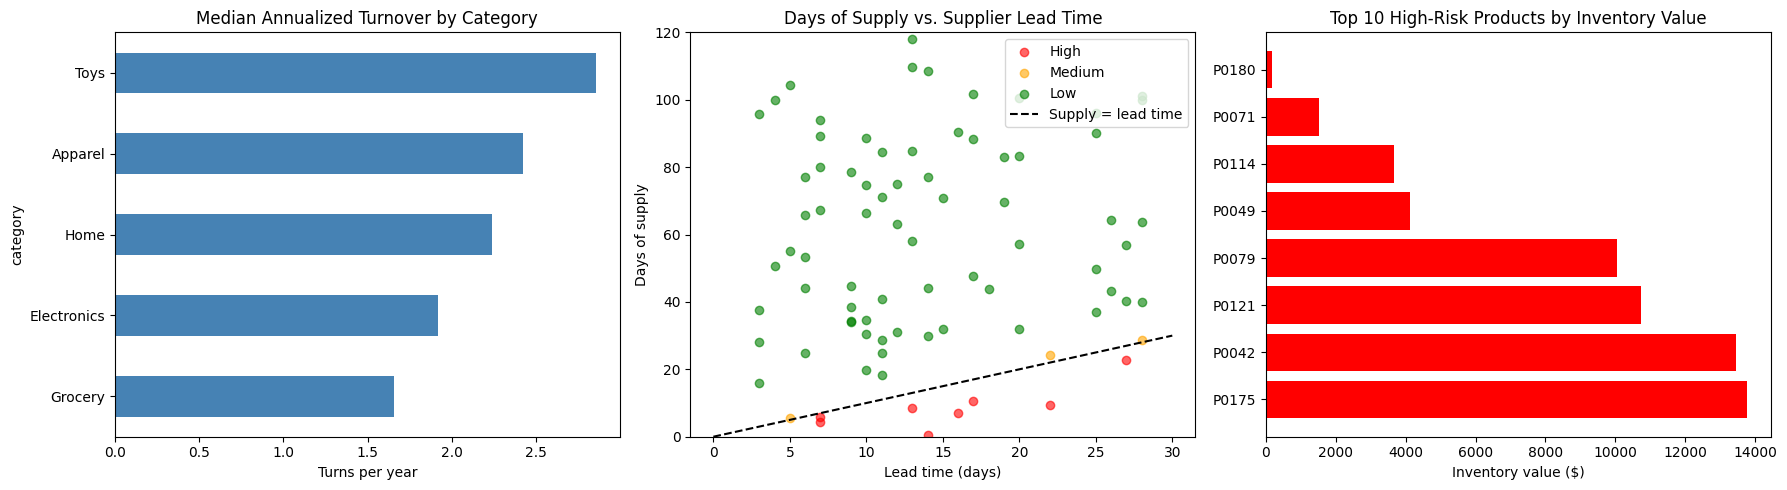

,products,median_turnover,slow_moving,high_risk
category,,,,
Apparel,47,2.4,30,2
Electronics,38,1.9,24,1
Grocery,32,1.7,24,0
Home,49,2.2,32,4
Toys,34,2.9,21,1


In [6]:
results, issues = analyze_inventory_v2(inventory_df, as_of_date='2026-11-20')
plot_inventory(results)

summary = (results.groupby('category')
           .agg(products=('product_id', 'count'),
                median_turnover=('turnover_annualized', 'median'),
                slow_moving=('slow_moving', 'sum'),
                high_risk=('stockout_risk', lambda s: (s == 'High').sum()))
           .round(1))
summary

In [7]:
# Reorder list for the store manager: High-risk items, most valuable first
results.loc[results['stockout_risk'] == 'High',
            ['product_id', 'category', 'stock_level', 'days_of_supply', 'supplier_lead_time']] \
    .sort_values('days_of_supply').head(10).round(1)

,product_id,category,stock_level,days_of_supply,supplier_lead_time
180,P0180,Toys,2.0,0.4,14
49,P0049,Home,20.0,4.4,7
71,P0071,Electronics,11.0,5.9,7
79,P0079,Home,41.0,7.2,16
175,P0175,Apparel,47.0,8.4,13
42,P0042,Home,47.0,9.4,22
121,P0121,Home,53.0,10.5,17
114,P0114,Apparel,121.0,22.8,27


## Comparison summary

| | Vague prompt | Detailed prompt |
|---|---|---|
| Date handling | `datetime.now()`, strict parsing, **crashed** on mixed formats | `as_of_date` parameter (reproducible), `format='mixed', errors='coerce'`, bad dates reported |
| Turnover definition | sales ÷ stock, no time period | 30-day and annualized turnover, plus days of supply |
| Slow-moving | arbitrary `< 0.5` cutoff | business rule: >90 days supply or bottom 20% within category |
| Stockouts | yes/no only | High/Medium/Low using lead time + safety buffer |
| Error handling | none | column validation, safe division, negative stock flagged, issues dict returned |
| Visualizations | one histogram | 3 charts answering specific manager questions |